# Asymmetric nested alien task — HOLMES simulation

Tests the prediction that **asymmetric reward relevance produces asymmetric tree depth**,
and therefore an **RT asymmetry**: the safe species (B) is queried fast (stop at the species
node) while the radioactive species (A) is queried slowly (must descend to the clan to
resolve helpful vs harmful).

Structure (3 levels):
- **Species** (top): A = radioactive, B = safe. Reward-relevant.
- **Clan** (within A only, reward-relevant): A′ helpful (+health), A″ harmful (−health).
- **Clan within B**: exists perceptually but is **not** reward-relevant → should collapse.

Predictions: (1) HOLMES builds a deep A-subtree, shallow B-subtree; (2) RT (levels
traversed) is larger for A than B

Requires `hier_model_delta.py` or regular one 

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import hier_model_delta as H

np.random.seed(0)
C_A = '#D85A30'   # species A (coral)
C_B = '#1D9E75'   # species B (teal)

## 1. Task generator

Each alien = (species, clan, exemplar-noise). Features:
- `species` bit (A=0, B=1) — global body cue.
- clan cue is **branch-specific**: within A the clan is signalled on one feature block,
  within B on a different block (so you must know species to read the clan — tree-required).
- perceptual exemplar variability via extra noise features (defeats memorization).

Outcome = **health value**, which depends on species AND (for A) clan:
- A′ helpful → +1 ;  A″ harmful → 0 ;  B (either clan) → neutral/safe = 1 (clan irrelevant).
So the clan distinction carries reward **only within A**.

In [2]:
def make_asymmetric_task(n_exemplars=4, reps=30, seed=0, noise_feats=4, p_noise=0.15):
    rng = np.random.default_rng(seed)
    # 2 species x 2 clans = 4 leaves; n_exemplars perceptual variants each
    leaves = [(s, c) for s in range(2) for c in range(2)]
    trials = []
    for _ in range(reps):
        order = leaves * n_exemplars
        rng.shuffle(order)
        for (s, c) in order:
            trials.append((s, c))
    T = len(trials)
    species = np.array([t[0] for t in trials])
    clan    = np.array([t[1] for t in trials])

    # health outcome: reward-relevant clan ONLY within A (species 0)
    #   A' (s0,c0) helpful -> 1 ; A'' (s0,c1) harmful -> 0 ; B (s1,*) safe -> 1
    health = np.where(species == 0, 1 - clan, 1).astype(int)

    # feature encoding:
    #   f0: species bit
    #   f1,f2: clan cue for species A (active only when species==0), else 0
    #   f3,f4: clan cue for species B (active only when species==1), else 0
    #   noise features: perceptual exemplar variability
    #   last: outcome (health)
    nnoise = noise_feats
    F = np.zeros((1 + 2 + 2 + nnoise + 1, T), int)
    F[0] = species
    # branch-specific clan cues (one-hot-ish, only populated in the matching branch)
    F[1] = ((species == 0) & (clan == 0)).astype(int)
    F[2] = ((species == 0) & (clan == 1)).astype(int)
    F[3] = ((species == 1) & (clan == 0)).astype(int)
    F[4] = ((species == 1) & (clan == 1)).astype(int)
    for j in range(nnoise):
        F[5 + j] = (rng.random(T) < p_noise).astype(int)   # random exemplar noise
    oi = F.shape[0] - 1
    F[oi] = health
    return F, oi, species, clan, health

F, oi, species, clan, health = make_asymmetric_task()
print(f"trials: {F.shape[1]}, features: {F.shape[0]}, outcome idx: {oi}")
print(f"health by (species,clan):")
print(pd.DataFrame({'species':species,'clan':clan,'health':health})
      .groupby(['species','clan'])['health'].mean())

trials: 480, features: 10, outcome idx: 9
health by (species,clan):
species  clan
0        0       1.0
         1       0.0
1        0       1.0
         1       1.0
Name: health, dtype: float64


## 2. HOLMES runner

Run HOLMES on the trial sequence. Each level is reward-relevant only where the outcome
depends on it, so we expect the A-branch to be carved deeper than the B-branch.

In [15]:
def run_holmes(F, oi, alpha=2, delta=0.1, omega=2, nParticles=200, seed=0):
    nt = F.shape[1]
    np.random.seed(seed)
    out = H.full_hier_inference_loop(
        nTrials=nt, nParticles=nParticles, nFeatures=F.shape[0], alpha=alpha, omega=omega,
        f=F, max_depth=12, max_children=8, outcome_idx=oi,
        feedback_mask=np.ones_like(F, bool), random_seed=seed,
        length_normalize=False, depth_decay=delta)
    return out   # (particles, cEst, rEst, phiEst, cEst_levels, paths, weight_hist)

out = run_holmes(F, oi)
paths = out[5]
print("HOLMES run complete. paths shape:", paths.shape)

HOLMES run complete. paths shape: (200, 480, 12)


## 3. Depth of the inferred tree, by species (the core test)

For each trial in the asymptotic window, take the majority path depth. Split by species.
Prediction: **A-branch deeper than B-branch** (A′/A″ carved; B′/B″ collapsed).

Inferred tree depth by species (A=0, B=1):
          mean    sem
species              
0        2.537  0.051
1        1.389  0.113

A-branch depth 2.54 vs B-branch 1.39  -> asymmetry +1.15


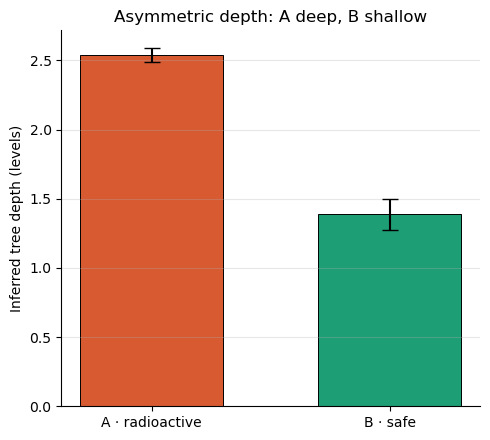

In [16]:
def majority_depth_per_trial(paths, window_frac=0.5):
    nP, nT, _ = paths.shape
    w0 = int(nT * window_frac)
    depth = np.full(nT, np.nan)
    for tt in range(w0, nT):
        ds = []
        for m in range(nP):
            v = np.where(paths[m, tt, :] >= 0)[0]
            if len(v): ds.append(v.max() + 1)
        if ds: depth[tt] = np.mean(ds)
    return depth

depth = majority_depth_per_trial(paths)
df = pd.DataFrame({'species': species, 'clan': clan, 'depth': depth}).dropna()
by_species = df.groupby('species')['depth'].agg(['mean','sem'])
print("Inferred tree depth by species (A=0, B=1):")
print(by_species.round(3))
print(f"\nA-branch depth {by_species.loc[0,'mean']:.2f} vs B-branch {by_species.loc[1,'mean']:.2f}"
      f"  -> asymmetry {by_species.loc[0,'mean']-by_species.loc[1,'mean']:+.2f}")

fig, ax = plt.subplots(figsize=(5,4.5))
ax.bar(['A · radioactive','B · safe'], by_species['mean'], yerr=by_species['sem'],
       color=[C_A, C_B], edgecolor='black', linewidth=0.7, capsize=6, width=0.6)
ax.set_ylabel('Inferred tree depth (levels)'); ax.set_title('Asymmetric depth: A deep, B shallow')
ax.spines[['top','right']].set_visible(False); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

## 4. Estimated RT by species (levels traversed)

RT proxy = depth of the path that must be resolved to answer the query. Under the asymmetric
structure, B needs only the species node (shallow → fast), A needs the clan (deep → slow).
We also split A by clan and B by clan to show B′≈B″ (undifferentiated) while A′,A″ differ.

     label  mean   sem
A′ helpful 3.013 0.013
A″ harmful 2.062 0.051
        B′ 1.555 0.160
        B″ 1.223 0.158


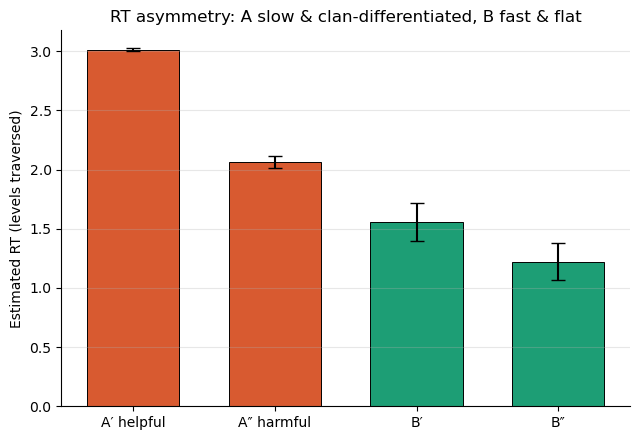

In [17]:
df['rt_proxy'] = df['depth']   # levels traversed = RT proxy (scale to ms with one constant)
cell = df.groupby(['species','clan'])['rt_proxy'].agg(['mean','sem']).reset_index()
labels = {(0,0):"A′ helpful",(0,1):"A″ harmful",(1,0):"B′",(1,1):"B″"}
cell['label'] = cell.apply(lambda r: labels[(r.species,r.clan)], axis=1)
print(cell[['label','mean','sem']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5,4.5))
cols = [C_A, C_A, C_B, C_B]
ax.bar(cell['label'], cell['mean'], yerr=cell['sem'], color=cols,
       edgecolor='black', linewidth=0.7, capsize=5, width=0.65)
ax.set_ylabel('Estimated RT (levels traversed)')
ax.set_title('RT asymmetry: A slow & clan-differentiated, B fast & flat')
ax.spines[['top','right']].set_visible(False); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()


## 5. RT asymmetry over learning

The A−B gap should **grow** as B is pruned and A is elaborated. Bin by trial and track
mean depth for each species across learning.

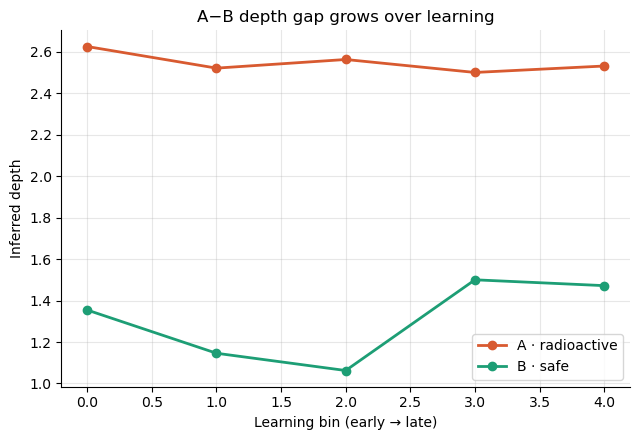

Gap by bin (A - B):
bin
0    1.271
1    1.375
2    1.500
3    1.000
4    1.059


In [18]:
def depth_over_learning(paths, species, nbins=5):
    nP, nT, _ = paths.shape
    rows = []
    for tt in range(nT):
        ds = []
        for m in range(nP):
            v = np.where(paths[m, tt, :] >= 0)[0]
            if len(v): ds.append(v.max()+1)
        if ds: rows.append((tt, species[tt], np.mean(ds)))
    d = pd.DataFrame(rows, columns=['trial','species','depth'])
    d['bin'] = pd.cut(d['trial'], nbins, labels=False)
    return d.groupby(['bin','species'])['depth'].mean().unstack()

learn = depth_over_learning(paths, species)
fig, ax = plt.subplots(figsize=(6.5,4.5))
ax.plot(learn.index, learn[0], '-o', color=C_A, label='A · radioactive', lw=2)
ax.plot(learn.index, learn[1], '-o', color=C_B, label='B · safe', lw=2)
ax.set_xlabel('Learning bin (early → late)'); ax.set_ylabel('Inferred depth')
ax.set_title('A−B depth gap grows over learning'); ax.legend()
ax.spines[['top','right']].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Gap by bin (A - B):")
print((learn[0] - learn[1]).round(3).to_string())

## 6. Behavior: can the health outcome be predicted, and where is the tree needed?

Predicting health for A requires the clan (helpful vs harmful); for B the species suffices.
We measure HOLMES's outcome-prediction accuracy by cell. Prediction should be good everywhere
once learned, but the *depth required* differs (that's the RT story above). This panel confirms
the task is learnable and that A's accuracy depends on resolving the clan.

Outcome-prediction accuracy by cell (asymptotic):
     label  correct
A′ helpful      1.0
A″ harmful      1.0
        B′      1.0
        B″      1.0


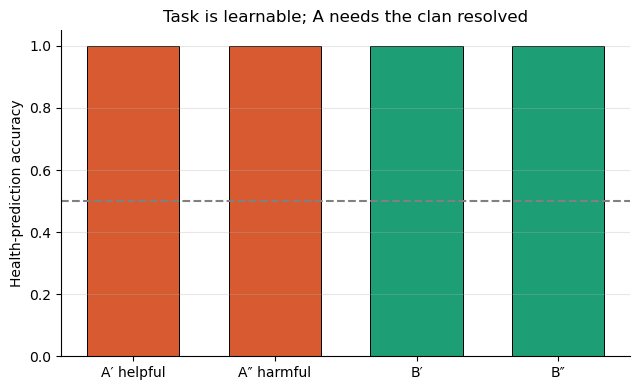

In [19]:
rEst = np.array(out[2])
w0 = len(species)//2
pred = (rEst[w0:] > 0.5).astype(int)
truth = health[w0:]
sp_w = species[w0:]; cl_w = clan[w0:]
acc = pd.DataFrame({'species':sp_w,'clan':cl_w,'correct':(pred==truth).astype(int)})
g = acc.groupby(['species','clan'])['correct'].mean().reset_index()
g['label'] = g.apply(lambda r: labels[(r.species,r.clan)], axis=1)
print("Outcome-prediction accuracy by cell (asymptotic):")
print(g[['label','correct']].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.5,4))
ax.bar(g['label'], g['correct'], color=[C_A,C_A,C_B,C_B], edgecolor='black', linewidth=0.7, width=0.65)
ax.axhline(0.5, ls='--', color='gray'); ax.set_ylim(0,1.05)
ax.set_ylabel('Health-prediction accuracy'); ax.set_title('Task is learnable; A needs the clan resolved')
ax.spines[['top','right']].set_visible(False); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

TREE SHAPE — modal node id and health-purity at each level, per cell:
(purity 1.0 = outcome fully determined once you reach this level)
      cell  level  node  n  health_purity
A′ helpful      0     0 60          0.750
A′ helpful      1     0 60          0.542
A′ helpful      2     0 60          0.986
A″ harmful      0     0 60          0.750
A″ harmful      1     0 60          0.542
        B′      0     0 60          0.750
        B′      1     0  9          0.542
        B′      2     0  9          0.986
        B′      3     0  9          1.000
        B″      0     0 60          0.750

RT readouts by cell — node_depth vs decision-resolution level:
           node_depth        resolve_level       
                 mean    sem          mean    sem
cell                                             
A′ helpful      3.000  0.000         3.000  0.000
A″ harmful      2.050  0.050         2.017  0.017
B′              1.517  0.167         1.300  0.093
B″              1.233  0.165         1

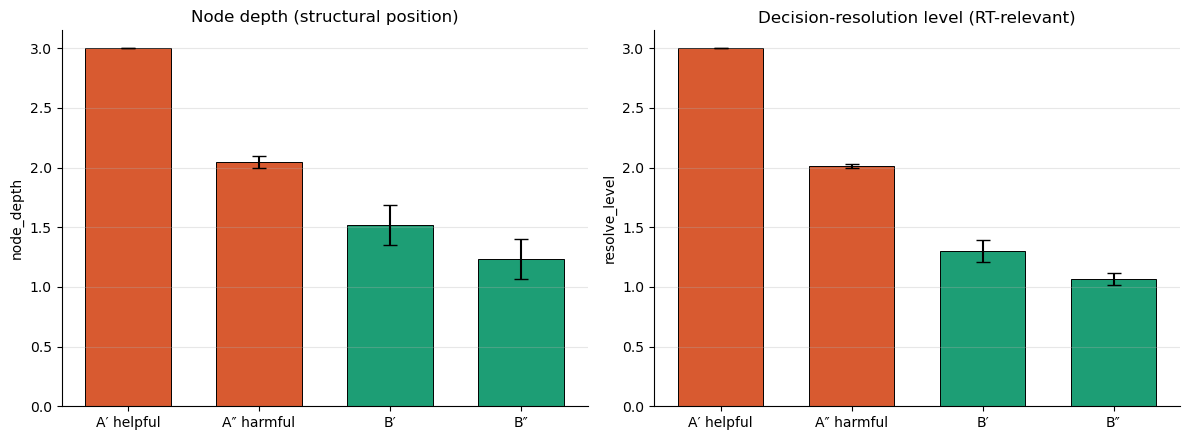


Interpretation:
 - If resolve_level is SMALL for the reward-critical A cells, HOLMES carves the
   important distinction near the root -> important = FAST (shallow), which would
   INVERT the 'descend deep for important ones' RT prediction.
 - If B′,B″ have equal, low resolve_level -> B collapses and is fast (as predicted).
 - Compare the two panels: node_depth and resolve_level can disagree, and
   resolve_level is the one that maps to reaction time.


In [20]:
# =====================================================================
# (a) Inspect the inferred tree shape per cell + (b) a decision-resolution RT
# readout (levels needed to PREDICT the outcome, not just node depth).
#
# node_depth   = how deep the leaf sits (structural position)
# resolve_level = the SHALLOWEST tree level at which the outcome becomes
#                 determined for that cell (i.e. once you've descended this far,
#                 the health outcome is certain). This is the RT-relevant quantity:
#                 fewer levels to resolve = faster decision.
# If reward-critical distinctions are carved NEAR THE ROOT, resolve_level is small
# (fast); if they require deep descent, resolve_level is large (slow).
# =====================================================================
from collections import Counter, defaultdict

def majority_path(paths, tt):
    ps = [tuple(paths[m, tt, :][paths[m, tt, :] >= 0]) for m in range(paths.shape[0])
          if (paths[m, tt, :] >= 0).any()]
    return Counter(ps).most_common(1)[0][0] if ps else ()

w0 = paths.shape[1] // 2
# majority path per trial (asymptotic window)
mp = {tt: majority_path(paths, tt) for tt in range(w0, paths.shape[1])}

# ---- (a) node label per level, per cell: what does each level encode? ----
# For each (species,clan) cell, find the modal node id at each level, and how pure
# that node is w.r.t. the health outcome (purity 1.0 = outcome fully determined here).
labels_cell = {(0,0):"A′ helpful",(0,1):"A″ harmful",(1,0):"B′",(1,1):"B″"}
records = []
maxL = max((len(p) for p in mp.values()), default=0)
for (s, c), lab in labels_cell.items():
    trials_here = [tt for tt in mp if species[tt]==s and clan[tt]==c]
    if not trials_here:
        continue
    # node id and outcome-purity at each level, aggregated over this cell's trials
    for L in range(maxL):
        node_ids = [mp[tt][L] for tt in trials_here if len(mp[tt]) > L]
        if len(node_ids) < 5:
            continue
        modal_node, cnt = Counter(node_ids).most_common(1)[0]
        # among ALL trials routing through this modal node at level L, how pure is health?
        cohort = [tt for tt in mp if len(mp[tt])>L and mp[tt][L]==modal_node]
        h = np.array([health[tt] for tt in cohort])
        purity = max(np.mean(h), 1-np.mean(h))   # 1.0 = outcome fully determined
        records.append(dict(cell=lab, level=L, node=int(modal_node),
                            n=len(node_ids), health_purity=round(float(purity),3)))
tree_tbl = pd.DataFrame(records)
print("TREE SHAPE — modal node id and health-purity at each level, per cell:")
print("(purity 1.0 = outcome fully determined once you reach this level)")
print(tree_tbl.to_string(index=False))

# ---- (b) decision-resolution RT: shallowest level where health becomes pure ----
def resolve_level(tt, thresh=0.95):
    """Shallowest level at which the majority-path node determines the outcome."""
    p = mp[tt]
    for L in range(len(p)):
        cohort = [u for u in mp if len(mp[u])>L and mp[u][L]==p[L]]
        h = np.array([health[u] for u in cohort])
        if len(h) and max(np.mean(h), 1-np.mean(h)) >= thresh:
            return L + 1          # levels traversed to resolve (1-indexed)
    return len(p) if p else np.nan

rr = pd.DataFrame({
    'species': [species[tt] for tt in mp],
    'clan':    [clan[tt] for tt in mp],
    'node_depth':    [len(mp[tt]) for tt in mp],
    'resolve_level': [resolve_level(tt) for tt in mp],
}).dropna()
rr['cell'] = rr.apply(lambda r: labels_cell[(int(r.species),int(r.clan))], axis=1)

summ = rr.groupby('cell')[['node_depth','resolve_level']].agg(['mean','sem'])
print("\nRT readouts by cell — node_depth vs decision-resolution level:")
print(summ.round(3).to_string())

# ---- plot both side by side ----
order = ["A′ helpful","A″ harmful","B′","B″"]
cols = [C_A, C_A, C_B, C_B]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in [(axes[0],'node_depth','Node depth (structural position)'),
                          (axes[1],'resolve_level','Decision-resolution level (RT-relevant)')]:
    m = [rr[rr.cell==o][metric].mean() for o in order]
    e = [rr[rr.cell==o][metric].sem() for o in order]
    ax.bar(order, m, yerr=e, color=cols, edgecolor='black', linewidth=0.7, capsize=5, width=0.65)
    ax.set_ylabel(metric); ax.set_title(title)
    ax.spines[['top','right']].set_visible(False); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

print("\nInterpretation:")
print(" - If resolve_level is SMALL for the reward-critical A cells, HOLMES carves the")
print("   important distinction near the root -> important = FAST (shallow), which would")
print("   INVERT the 'descend deep for important ones' RT prediction.")
print(" - If B′,B″ have equal, low resolve_level -> B collapses and is fast (as predicted).")
print(" - Compare the two panels: node_depth and resolve_level can disagree, and")
print("   resolve_level is the one that maps to reaction time.")